# DSCI 552 — Homework 6

**Name:** Vaidik Danda
**GitHub Username:** vaidikdanda-png
**USC ID:** 6930440811

## Imports

In [1]:
import os
import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Tree‑Based Methods
### 1(a) APS Failure data
The data is loaded with relative paths from `../data/aps_failure/`. If the files are missing, the cell tries to
download them from UCI.

In [2]:
APS_DIR = "../data/aps_failure"
TRAIN_FILE = APS_DIR + "/aps_failure_training_set.csv"
TEST_FILE = APS_DIR + "/aps_failure_test_set.csv"

if not (os.path.exists(TRAIN_FILE) and os.path.exists(TEST_FILE)):
    os.makedirs(APS_DIR, exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/421/aps+failure+at+scania+trucks.zip"
    print("Downloading", url)
    with urllib.request.urlopen(url, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for m in z.namelist():
            base = m.split("/")[-1]
            if base in ("aps_failure_training_set.csv", "aps_failure_test_set.csv"):
                with open(APS_DIR + "/" + base, "wb") as f:
                    f.write(z.read(m))


def read_aps(path):
    # the files start with a license header; the data starts at the line beginning with "class,"
    with open(path, encoding="latin-1") as f:
        for i, line in enumerate(f):
            if line.startswith("class,"):
                break
    return pd.read_csv(path, skiprows=i, na_values="na")


train = read_aps(TRAIN_FILE)
test = read_aps(TEST_FILE)
FEATURES = [c for c in train.columns if c != "class"]
print("Training set:", train.shape, "| Test set:", test.shape, "| Features:", len(FEATURES))
train.iloc[:5, :8]

Training set: (60000, 171) | Test set: (16000, 171) | Features: 170


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0


### 1(b) Data preparation
#### i. Missing values

**Common techniques for missing data:**
- **Deletion** — drop rows (listwise) or columns with missing values. Simple, but wastes data and can bias results
  when values are not missing completely at random.
- **Simple imputation** — replace missing values with the mean, median or mode of the feature. Fast; the median is
  robust to skewed features and outliers.
- **k‑nearest‑neighbour imputation** — fill a value from the most similar rows.
- **Model‑based / iterative imputation (MICE)** — predict each feature with missing values from the others,
  iterating until the values stabilize.
- **Missing‑indicator features** — add a 0/1 column marking missingness, so the model can use the fact that a value was
  missing.
- **Models that handle missing values natively** — e.g. XGBoost learns a default direction for missing values at
  each split.

**Chosen method: median imputation.** Almost every row has at least one missing value, so deleting rows is not an
option. The features are counters and histogram bins that are heavily right‑skewed, so the median is a better
"typical value" than the mean, and it is cheap on 60,000 × 170 data. Following footnote 1, the training set is
imputed with training medians and the test set is imputed with **test‑set** medians.

In [3]:
X_train_raw, X_test_raw = train[FEATURES], test[FEATURES]
y_train = (train["class"] == "pos").astype(int).values
y_test = (test["class"] == "pos").astype(int).values

miss = X_train_raw.isna().mean()
print(f"Missing cells in training set: {100 * X_train_raw.isna().values.mean():.1f}%")
print(f"Rows with at least one missing value: {100 * X_train_raw.isna().any(axis=1).mean():.1f}%")
print(f"Features with > 50% missing: {(miss > 0.5).sum()} | features with no missing values: {(miss == 0).sum()}")

X_train = pd.DataFrame(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X_train_raw),
                       columns=FEATURES)
X_test = pd.DataFrame(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X_test_raw),
                      columns=FEATURES)
X_train, X_test = X_train.fillna(0), X_test.fillna(0)

Missing cells in training set: 8.3%
Rows with at least one missing value: 99.0%
Features with > 50% missing: 8 | features with no missing values: 1


#### ii. Coefficient of variation $CV = s/m$ (imputed training set)

In [4]:
mean, std = X_train.mean(), X_train.std(ddof=1)
cv = (std / mean).replace([np.inf, -np.inf], np.nan)
cv = cv.dropna().sort_values(ascending=False)
pd.concat([cv.head(5), cv.tail(5)]).to_frame("CV (5 highest, 5 lowest)")

,"CV (5 highest, 5 lowest)"
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
bo_000,0.792383
bp_000,0.753392
bq_000,0.718534
br_000,0.689112
cd_000,0.000000


#### iii. Correlation matrix

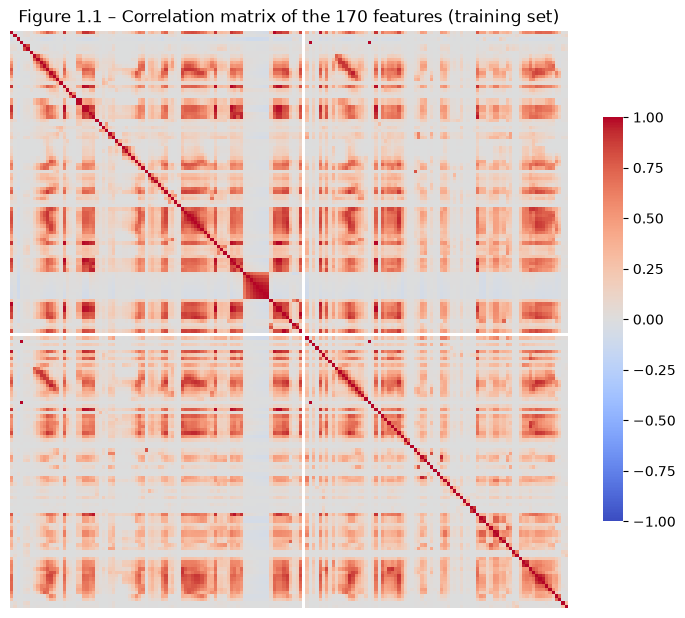

In [5]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Figure 1.1 – Correlation matrix of the 170 features (training set)")
plt.show()

#### iv. ⌊√170⌋ = 13 features with the highest CV
The features are extremely skewed, so the plots use $\log(1+x)$. For the scatter plots, all positive trucks and a
random sample of 3,000 negative trucks are shown so the positive class is visible.

k = 13: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


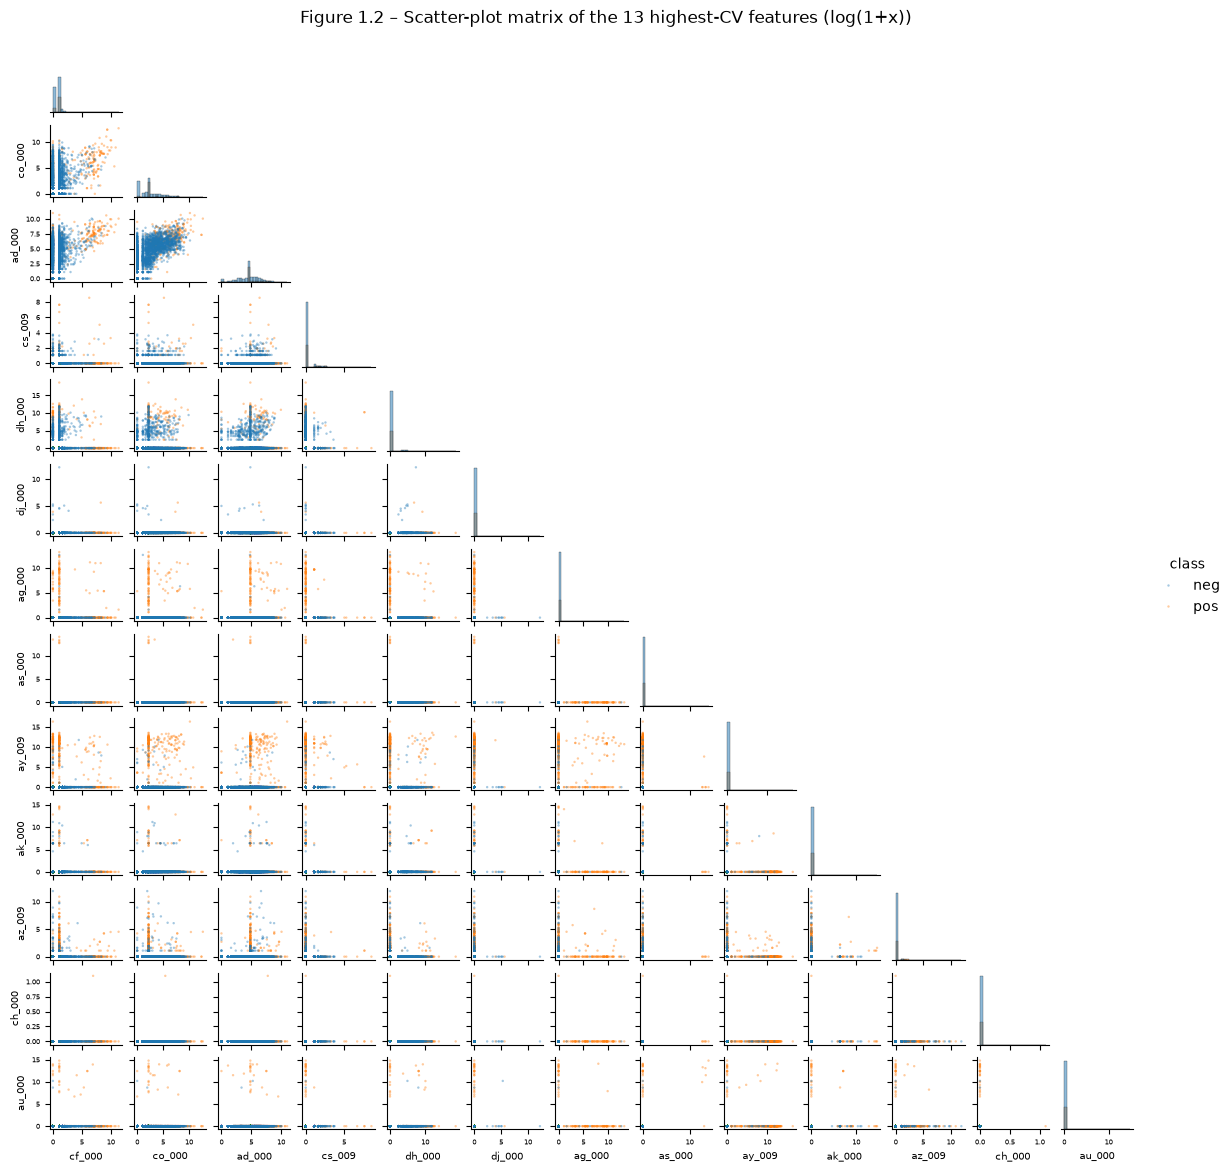

In [6]:
k = int(np.floor(np.sqrt(170)))
top_cv = cv.head(k).index.tolist()
print(f"k = {k}:", top_cv)

plot_df = np.log1p(X_train[top_cv].clip(lower=0))
plot_df["class"] = np.where(y_train == 1, "pos", "neg")
sample = pd.concat([plot_df[plot_df["class"] == "pos"],
                    plot_df[plot_df["class"] == "neg"].sample(3000, random_state=RANDOM_STATE)])
pp = sns.pairplot(sample, vars=top_cv, hue="class", hue_order=["neg", "pos"], corner=True, height=0.9,
                  plot_kws={"s": 3, "alpha": 0.4, "linewidth": 0}, diag_kind="hist", diag_kws={"bins": 25})
for ax in pp.axes.flatten():
    if ax is not None:
        ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7); ax.tick_params(labelsize=5)
pp.figure.suptitle(f"Figure 1.2 – Scatter-plot matrix of the {k} highest-CV features (log(1+x))", y=1.01)
plt.show()

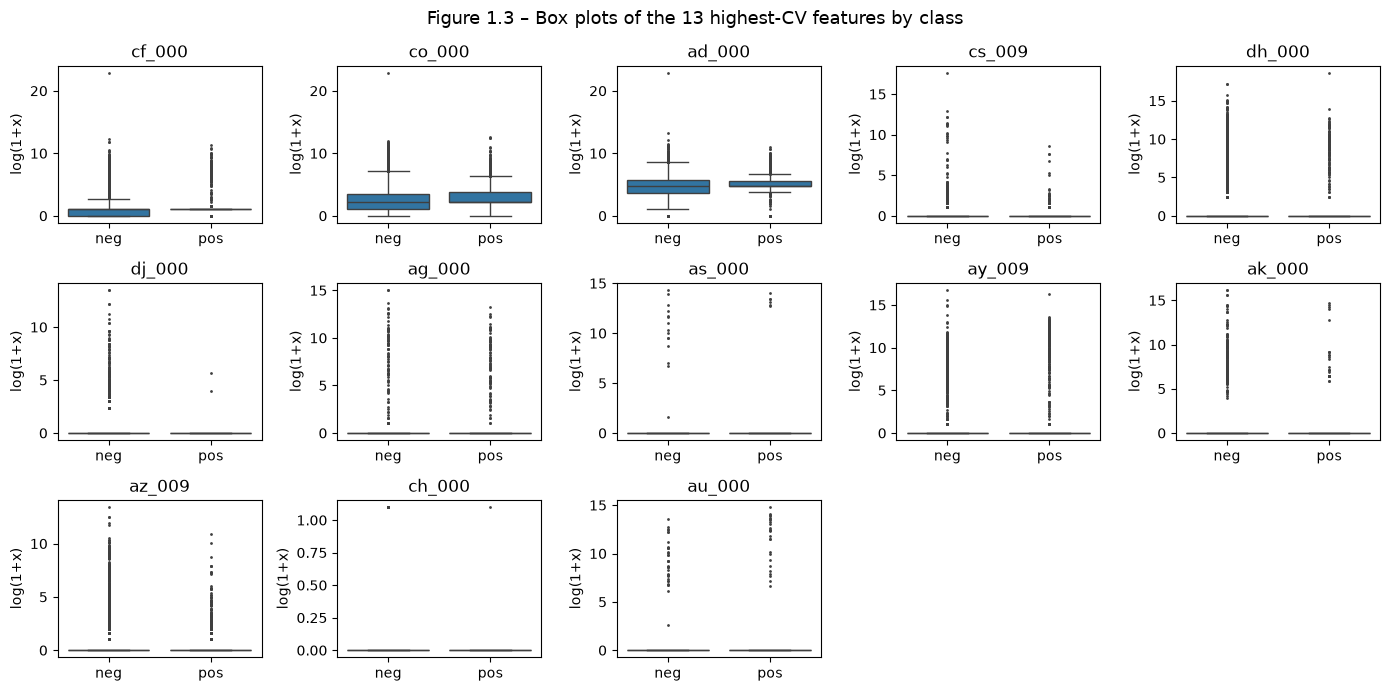

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top_cv):
    sns.boxplot(x=plot_df["class"], y=plot_df[col], order=["neg", "pos"], ax=ax, fliersize=1)
    ax.set(title=col, xlabel="", ylabel="log(1+x)")
for ax in axes.ravel()[k:]:
    ax.axis("off")
fig.suptitle(f"Figure 1.3 – Box plots of the {k} highest-CV features by class", fontsize=13)
plt.tight_layout()
plt.show()

**Answer 1(b)iv.** No — scatter plots alone cannot tell us whether these features are significant. The 13 highest‑CV
features (cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000) have
CVs from about 245 down to the tens: they are almost always 0 or small, with a few huge values, which is why the plots
need a log scale. The positive and negative trucks overlap heavily in the scatter plots, and the box plots show only
that some of these features tend to be larger for failed trucks. A scatter plot looks at one or two features at a
time, ignores the strong correlations between features (Figure 1.1) and gives no measure of uncertainty, and a high CV
only means a feature varies a lot relative to its mean, not that it predicts the class. Significance has to be judged
from a fitted model (coefficients and tests, or variable importance).

#### v. Positive and negative data

In [8]:
counts = pd.DataFrame({"train": pd.Series(y_train).value_counts(), "test": pd.Series(y_test).value_counts()})
counts.index = counts.index.map({0: "negative", 1: "positive"})
counts.loc["% positive"] = (100 * counts.loc["positive"] / counts.sum()).round(2)
counts

,train,test
negative,59000.00,15625.00
positive,1000.00,375.00
% positive,1.67,2.34


**Answer 1(b)v.** Yes, the data set is highly imbalanced. The training set has 59,000 negative and 1,000 positive
trucks (1.67% positive, 59 negatives per positive); the test set has 15,625 negative and 375 positive (2.34%). A
classifier that always predicts "negative" would already be about 98.3% accurate on the training set, so accuracy
alone is misleading here; the confusion matrix and AUC are more useful.

### Evaluation helper
Reports the confusion matrix, ROC curve, AUC and misclassification rate (threshold 0.5) on the training and test sets.

In [9]:
RESULTS = []


def evaluate(model, name, fig_no):
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for j, (split, X, y) in enumerate([("train", X_train, y_train), ("test", X_test, y_test)]):
        p = model.predict_proba(X)[:, 1]
        pred = (p >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        auc = roc_auc_score(y, p)
        fpr, tpr, _ = roc_curve(y, p)
        axes[0].plot(fpr, tpr, label=f"{split} (AUC = {auc:.4f})")
        sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cbar=False, cmap="Blues", ax=axes[j + 1],
                    xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
        axes[j + 1].set(title=f"{split} confusion matrix", xlabel="predicted", ylabel="actual")
        rows.append({"model": name, "set": split, "AUC": auc, "misclassification": (fp + fn) / len(y),
                     "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
    axes[0].legend(loc="lower right")
    fig.suptitle(f"Figure {fig_no} – {name}", fontsize=12)
    plt.tight_layout()
    plt.show()
    df = pd.DataFrame(rows)
    RESULTS.append(df)
    return df.round(5)

### 1(c) Random forest without compensating for class imbalance

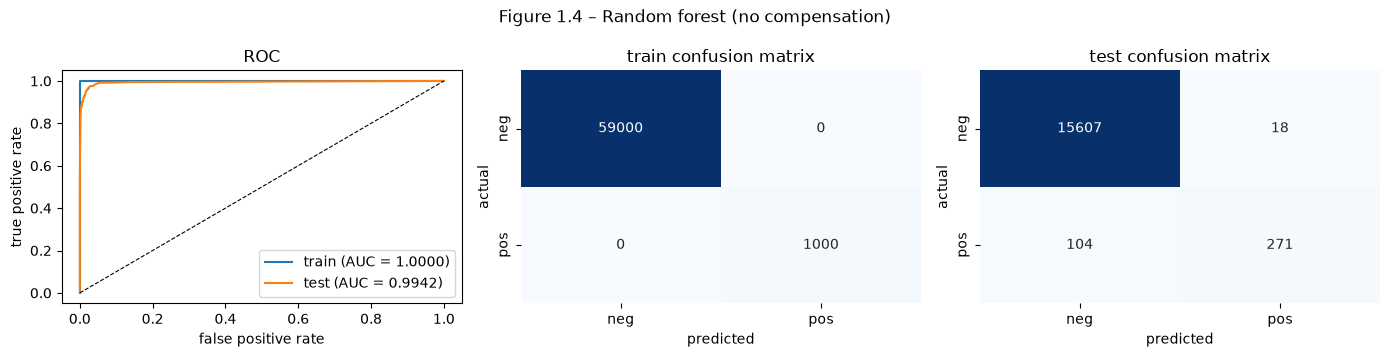

OOB error estimate: 0.00577 | test misclassification: 0.00762


,model,set,AUC,misclassification,TN,FP,FN,TP
0,Random forest (no compensation),train,1.00000,0.00000,59000,0,0,1000
1,Random forest (no compensation),test,0.99423,0.00762,15607,18,104,271


In [10]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
rf_res = evaluate(rf, "Random forest (no compensation)", "1.4")
oob_rf = 1 - rf.oob_score_
print(f"OOB error estimate: {oob_rf:.5f} | test misclassification: {rf_res.loc[1, 'misclassification']:.5f}")
rf_res

**Answer 1(c).**

| | train | test |
|---|---|---|
| AUC | 1.00000 | 0.99423 |
| misclassification | 0.00000 | 0.00762 |
| FP / FN | 0 / 0 | 18 / 104 |

The forest fits the training set perfectly (no errors, AUC = 1), so the training results say little about performance
on new data. The **OOB error estimate is 0.00577**, close to the **test error of 0.00762**. OOB is slightly lower
partly because the test set has a higher share of positives (2.34% vs 1.67%), and most errors are on positives. The
low error rate hides the real problem: **104 of the 375 failed trucks in the test set (28%) are missed**, while only 18
healthy trucks are flagged.

### 1(d) Random forest with class‑imbalance compensation
**How random forests handle class imbalance:**
- **Class weights / cost‑sensitive learning** — weight the minority class more in the impurity calculation and in the
  leaf votes (scikit‑learn `class_weight="balanced"` or `"balanced_subsample"`, which re‑computes weights in every
  bootstrap sample).
- **Balanced random forest** — draw each bootstrap sample so it contains equal numbers of both classes
  (down‑sampling the majority class per tree).
- **Over‑sampling the minority class** — e.g. random over‑sampling or SMOTE before training.
- **Moving the decision threshold** — predict positive when the vote share is above a value lower than 0.5.

**Chosen method:** `class_weight="balanced_subsample"`, so each positive counts 59× more than a negative. With fully
grown trees every leaf is pure and the weights would barely change the votes, so the trees are also limited to at
least 10 samples per leaf; this lets the class weights shift the leaf predictions toward the positive class.

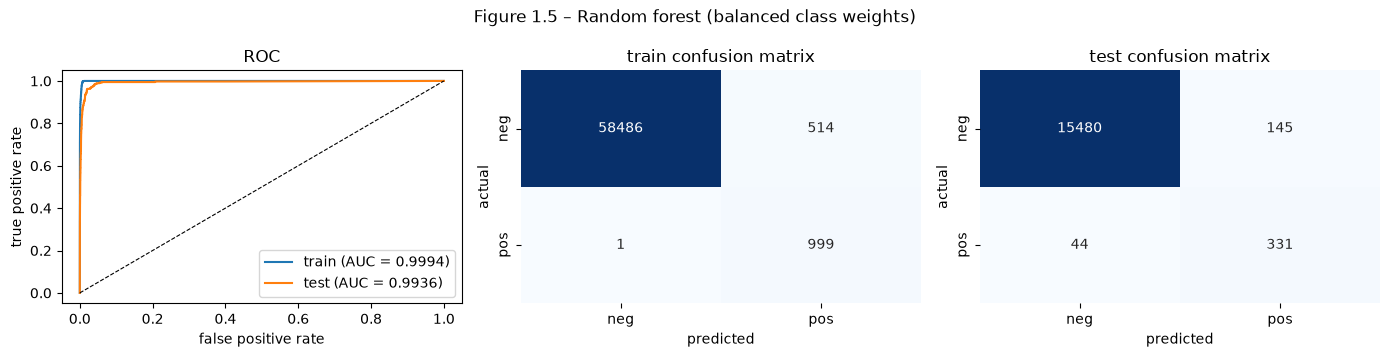

OOB error estimate: 0.01232 | test misclassification: 0.01181


,model,set,AUC,misclassification,TN,FP,FN,TP
0,Random forest (balanced class weights),train,0.99940,0.00858,58486,514,1,999
1,Random forest (balanced class weights),test,0.99364,0.01181,15480,145,44,331


In [11]:
rf_bal = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=10,
                                oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf_bal.fit(X_train, y_train)
rfb_res = evaluate(rf_bal, "Random forest (balanced class weights)", "1.5")
oob_rfb = 1 - rf_bal.oob_score_
print(f"OOB error estimate: {oob_rfb:.5f} | test misclassification: {rfb_res.loc[1, 'misclassification']:.5f}")
rfb_res

**Answer 1(d).**

| test set | no compensation (1c) | balanced class weights (1d) |
|---|---|---|
| AUC | 0.99423 | 0.99364 |
| misclassification | 0.00762 | 0.01181 |
| FP / FN | 18 / 104 | 145 / 44 |
| recall on positives | 72.3% | 88.3% |
| OOB error | 0.00577 | 0.01232 |

Compensating for the imbalance cuts the missed failures from 104 to 44 (recall rises from 72% to 88%), at the cost of
more false alarms (18 → 145). The overall misclassification rate goes up (0.0076 → 0.0118) because there are many more
negatives, but the compensated model is far more useful for catching failures. The AUC barely changes, since AUC
measures how well the trucks are ranked over all thresholds, and the class weights mainly shift the effective
threshold. On the training set the compensated forest is no longer perfect (514 FP, 1 FN) because of the minimum leaf
size. Its **OOB error (0.01232) is very close to its test error (0.01181)**.

### 1(e) XGBoost (model tree with L1‑penalized logistic regression), no compensation
XGBoost with the `binary:logistic` objective fits each tree to the gradient of the logistic loss, and its leaf values
are fitted with an **L1 penalty** (`reg_alpha` = α) as well as the default L2 penalty. α is chosen with **5‑fold
stratified cross‑validation** (by AUC); the CV misclassification error at the chosen α is the CV estimate of the error.

In [12]:
ALPHAS = [0, 0.01, 0.1, 1, 10]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_xgb(alpha=0.0):
    return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         objective="binary:logistic", tree_method="hist", eval_metric="logloss",
                         reg_alpha=alpha, n_jobs=-1, random_state=RANDOM_STATE)


def cv_table(grid, key):
    r = pd.DataFrame(grid.cv_results_)
    return pd.DataFrame({"alpha": r[key], "CV AUC": r["mean_test_auc"], "CV error": 1 - r["mean_test_acc"]}).round(5)


xgb_grid = GridSearchCV(make_xgb(), {"reg_alpha": ALPHAS}, cv=cv5, scoring={"auc": "roc_auc", "acc": "accuracy"},
                        refit="auc")
xgb_grid.fit(X_train, y_train)
xgb_cv = cv_table(xgb_grid, "param_reg_alpha")
best_a = xgb_grid.best_params_["reg_alpha"]
cv_err_xgb = 1 - xgb_grid.cv_results_["mean_test_acc"][xgb_grid.best_index_]
print("Chosen alpha:", best_a)
xgb_cv

Chosen alpha: 1


,alpha,CV AUC,CV error
0,0.00,0.98821,0.00553
1,0.01,0.98881,0.00563
2,0.10,0.98852,0.00573
3,1.00,0.98895,0.00585
4,10.00,0.98878,0.00658


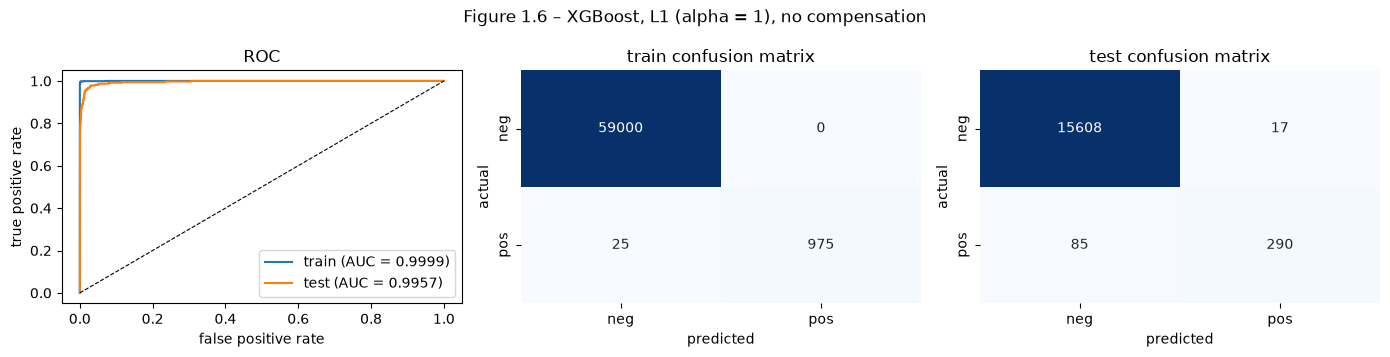

5-fold CV error: 0.00585 | test misclassification: 0.00638


,model,set,AUC,misclassification,TN,FP,FN,TP
0,"XGBoost, L1 (alpha = 1), no compensation",train,0.99991,0.00042,59000,0,25,975
1,"XGBoost, L1 (alpha = 1), no compensation",test,0.99566,0.00638,15608,17,85,290


In [13]:
xgb_res = evaluate(xgb_grid.best_estimator_, f"XGBoost, L1 (alpha = {best_a}), no compensation", "1.6")
print(f"5-fold CV error: {cv_err_xgb:.5f} | test misclassification: {xgb_res.loc[1, 'misclassification']:.5f}")
xgb_res

**Answer 1(e).** All values of α give almost the same CV AUC (0.988–0.989); **α = 1** has the highest, so it is chosen.

| | train | test |
|---|---|---|
| AUC | 0.99991 | 0.99566 |
| misclassification | 0.00042 | 0.00638 |
| FP / FN | 0 / 25 | 17 / 85 |

The **5‑fold CV error (0.00585)** is close to the **test error (0.00638)**, so cross‑validation estimates the test error
well. XGBoost has the best test AUC and the lowest test error of all the models, but without compensation it still
misses 85 of the 375 failed trucks (recall 77%).

### 1(f) XGBoost with SMOTE
**Right vs. wrong way to cross‑validate.** SMOTE creates synthetic positives by interpolating between real positives.
If SMOTE is applied to the whole training set *before* splitting into folds, synthetic points made from a validation
point's neighbours end up in the training folds, and the validation folds contain synthetic points too. The CV
estimate is then far too optimistic. The **right way** is to apply SMOTE only to the training folds inside each CV
split, and validate on the untouched original data. This is done with an `imblearn` pipeline, whose sampler runs only
during `fit`. The final model applies SMOTE to the **full** training set. Training‑set results below are on the
original (not synthetic) training data.

In [14]:
smote_pipe = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)), ("xgb", make_xgb())])
smote_grid = GridSearchCV(smote_pipe, {"xgb__reg_alpha": ALPHAS}, cv=cv5,
                          scoring={"auc": "roc_auc", "acc": "accuracy"}, refit="auc")
smote_grid.fit(X_train, y_train)    # refit = SMOTE on the full training set + XGBoost
smote_cv = cv_table(smote_grid, "param_xgb__reg_alpha")
best_a_s = smote_grid.best_params_["xgb__reg_alpha"]
cv_err_smote = 1 - smote_grid.cv_results_["mean_test_acc"][smote_grid.best_index_]
print("Chosen alpha:", best_a_s)
smote_cv

Chosen alpha: 0.1


,alpha,CV AUC,CV error
0,0.00,0.98562,0.00730
1,0.01,0.98603,0.00747
2,0.10,0.98642,0.00742
3,1.00,0.98625,0.00745
4,10.00,0.98639,0.00853


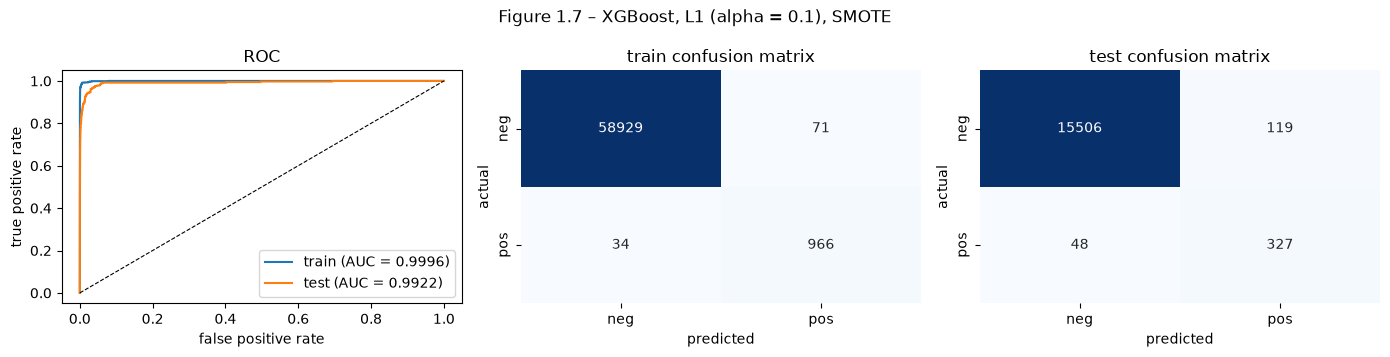

5-fold CV error (right way): 0.00742 | test misclassification: 0.01044


,model,set,AUC,misclassification,TN,FP,FN,TP
0,"XGBoost, L1 (alpha = 0.1), SMOTE",train,0.99960,0.00175,58929,71,34,966
1,"XGBoost, L1 (alpha = 0.1), SMOTE",test,0.99216,0.01044,15506,119,48,327


In [15]:
smote_res = evaluate(smote_grid.best_estimator_, f"XGBoost, L1 (alpha = {best_a_s}), SMOTE", "1.7")
print(f"5-fold CV error (right way): {cv_err_smote:.5f} | test misclassification: {smote_res.loc[1, 'misclassification']:.5f}")
smote_res

### Comparison of all models (test set)

In [16]:
summary = pd.concat(RESULTS).query("set == 'test'").drop(columns="set").set_index("model")
summary["recall (pos)"] = summary["TP"] / (summary["TP"] + summary["FN"])
summary["OOB / CV error estimate"] = [oob_rf, oob_rfb, cv_err_xgb, cv_err_smote]
summary.round(5)

,AUC,misclassification,TN,FP,FN,TP,recall (pos),OOB / CV error estimate
model,,,,,,,,
Random forest (no compensation),0.99423,0.00762,15607,18,104,271,0.72267,0.00577
Random forest (balanced class weights),0.99364,0.01181,15480,145,44,331,0.88267,0.01232
"XGBoost, L1 (alpha = 1), no compensation",0.99566,0.00638,15608,17,85,290,0.77333,0.00585
"XGBoost, L1 (alpha = 0.1), SMOTE",0.99216,0.01044,15506,119,48,327,0.87200,0.00742


**Answer 1(f) — uncompensated vs. SMOTE.** CV chose **α = 0.1** for the SMOTE model.

| test set | XGBoost, no compensation (1e) | XGBoost + SMOTE (1f) |
|---|---|---|
| AUC | 0.99566 | 0.99216 |
| misclassification | 0.00638 | 0.01044 |
| FP / FN | 17 / 85 | 119 / 48 |
| recall on positives | 77.3% | 87.2% |
| 5‑fold CV error | 0.00585 | 0.00742 |

With SMOTE, XGBoost trains on as many positives as negatives, so it predicts "positive" much more readily: missed
failures drop from 85 to 48 (recall 77% → 87%), while false alarms rise from 17 to 119. Overall misclassification and
AUC are slightly worse, because the many extra false positives outweigh the fewer false negatives in a set that is 98%
negative. The right‑way CV error (0.00742) is a little below the test error (0.01044); it is estimated on folds of the
training set, which has a lower share of positives than the test set. Since a missed failure is much more expensive
than an unnecessary inspection, the compensated models (balanced random forest and SMOTE + XGBoost) are the more
useful ones in practice, with the balanced forest catching the most failures (331 of 375).

# 2. ISLR 6.6.3 (Chapter 6, Exercise 3)
We estimate the regression coefficients by minimizing $\sum_{i=1}^{n}\big(y_i-\beta_0-\sum_{j=1}^{p}\beta_j x_{ij}\big)^2$
subject to $\sum_{j=1}^{p}|\beta_j| \le s$, and increase $s$ from 0.

At $s = 0$ all $\beta_j = 0$ (the null model). As $s$ grows the constraint loosens, the model becomes more flexible, and
at a large enough $s$ it is the least‑squares fit.

**(a) Training RSS: (iv) steadily decreases.** A larger $s$ allows every solution that was allowed before plus more, so
the minimized training RSS can only go down until it reaches the least‑squares RSS.

**(b) Test RSS: (ii) decreases initially, then eventually starts increasing in a U shape.** At first the extra
flexibility captures real signal and the test error falls; once the model starts fitting noise (overfitting) the test
error rises again.

**(c) Variance: (iii) steadily increases.** The null model has zero variance; as the coefficients are less
constrained they depend more on the particular training set.

**(d) Squared bias: (iv) steadily decreases.** A more flexible model can approximate the true relationship more
closely, so the bias goes down.

**(e) Irreducible error: (v) remains constant.** $\mathrm{Var}(\epsilon)$ does not depend on the model at all.

# 3. ISLR 6.6.5 (Chapter 6, Exercise 5)
Setting: $n = p = 2$, $x_{11} = x_{12}$, $x_{21} = x_{22}$, $y_1 + y_2 = 0$, $x_{11} + x_{21} = 0$, $x_{12} + x_{22} = 0$, so
$\hat\beta_0 = 0$. Write $x_{11}=x_{12}=a$, so $x_{21}=x_{22}=-a$, and $y_2 = -y_1$.

**(a) Ridge optimization problem**
$$\min_{\beta_1,\beta_2}\; (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2)$$

**(b) Ridge gives $\hat\beta_1=\hat\beta_2$.** Substituting the setting, the objective becomes
$$f(\beta_1,\beta_2)=(y_1-a(\beta_1+\beta_2))^2+(-y_1+a(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)
=2\big(y_1-a(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2).$$
Setting the partial derivatives to zero:
$$\frac{\partial f}{\partial\beta_1}=-4a\big(y_1-a(\beta_1+\beta_2)\big)+2\lambda\beta_1=0,\qquad
\frac{\partial f}{\partial\beta_2}=-4a\big(y_1-a(\beta_1+\beta_2)\big)+2\lambda\beta_2=0.$$
Subtracting the two equations gives $2\lambda(\beta_1-\beta_2)=0$, and since $\lambda>0$, $\hat\beta_1=\hat\beta_2$.
(Solving, $\hat\beta_1=\hat\beta_2=\dfrac{2ay_1}{4a^2+\lambda}$. Because $f$ is strictly convex, this is the unique
solution.)

**(c) Lasso optimization problem**
$$\min_{\beta_1,\beta_2}\; (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|)$$

**(d) The lasso coefficients are not unique.** In the constraint form, minimize
$\text{RSS}=2\big(y_1-a(\beta_1+\beta_2)\big)^2$ subject to $|\beta_1|+|\beta_2|\le s$.
- The RSS depends on $\beta_1,\beta_2$ only through $\beta_1+\beta_2$, so its contours are the lines
  $\beta_1+\beta_2=c$. These are **parallel to the edges** $\beta_1+\beta_2=\pm s$ of the lasso diamond.
- The least‑squares solution is any point on the line $\beta_1+\beta_2=y_1/a$. Suppose $y_1/a>0$ and
  $s<y_1/a$ (otherwise the least‑squares solutions themselves are feasible and still not unique).
- The smallest RSS inside the diamond is then reached on the whole edge where the RSS contour touches it:
$$\hat\beta_1+\hat\beta_2=s,\qquad \hat\beta_1\ge0,\ \hat\beta_2\ge0.$$
- Every point on this line segment gives the same RSS and the same $|\beta_1|+|\beta_2|=s$, so there are infinitely
  many lasso solutions. (If $y_1/a<0$, the solutions are the edge $\hat\beta_1+\hat\beta_2=-s$ with
  $\hat\beta_1,\hat\beta_2\le0$.)

# 4. ISLR 8.4.5 (Chapter 8, Exercise 5)
Ten bootstrap estimates of $P(\text{Class is Red}\mid X)$: 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

**Answer.** With **majority vote**, 6 of the 10 trees say Red (probability > 0.5), so the final classification is
**Red**. With the **average probability**, the mean is 4.5 / 10 = 0.45 < 0.5, so the final classification is **Green**.

# 5. ISLR 9.7.3 (Chapter 9, Exercise 3)
Observations: Red = (3,4), (2,2), (4,4), (1,4); Blue = (2,1), (4,3), (4,1).

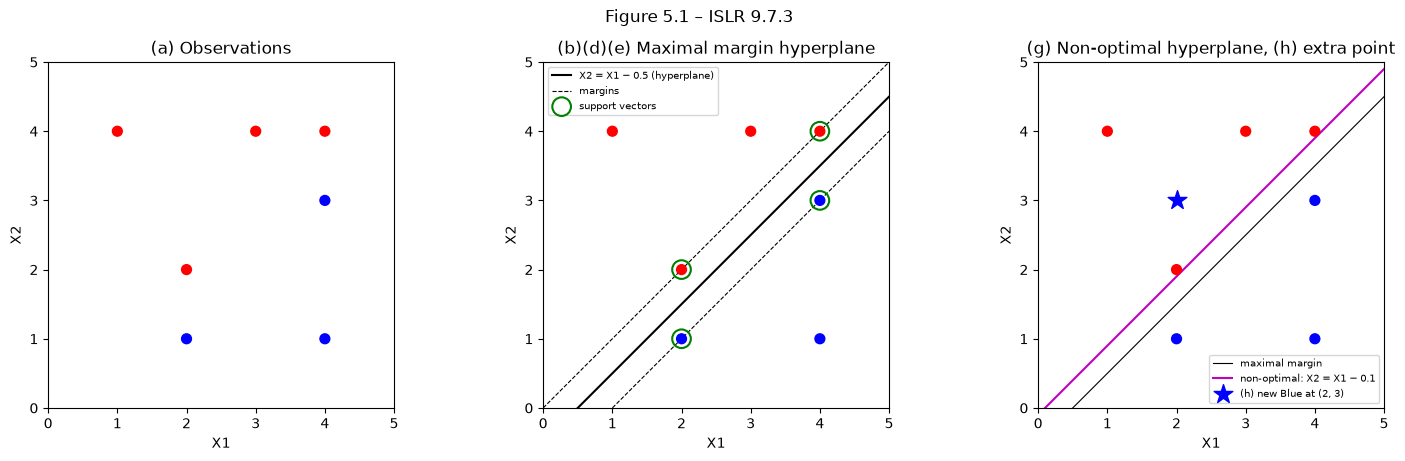

In [17]:
X5 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y5 = np.array(["Red"] * 4 + ["Blue"] * 3)
colors = np.where(y5 == "Red", "red", "blue")

xs = np.linspace(0, 5, 50)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
titles = ["(a) Observations", "(b)(d)(e) Maximal margin hyperplane", "(g) Non-optimal hyperplane, (h) extra point"]
for ax, t in zip(axes, titles):
    ax.scatter(X5[:, 0], X5[:, 1], c=colors, s=50, zorder=3)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="X1", ylabel="X2", title=t, aspect="equal")
axes[1].plot(xs, xs - 0.5, "k-", label="X2 = X1 − 0.5 (hyperplane)")
axes[1].plot(xs, xs, "k--", lw=0.8, label="margins")
axes[1].plot(xs, xs - 1, "k--", lw=0.8)
axes[1].scatter([2, 4, 2, 4], [2, 4, 1, 3], s=180, facecolors="none", edgecolors="green", lw=1.5,
                label="support vectors", zorder=4)
axes[1].legend(fontsize=7, loc="upper left")
axes[2].plot(xs, xs - 0.5, "k-", lw=0.8, label="maximal margin")
axes[2].plot(xs, xs - 0.1, "m-", label="non-optimal: X2 = X1 − 0.1")
axes[2].scatter([2], [3], c="blue", marker="*", s=200, zorder=4, label="(h) new Blue at (2, 3)")
axes[2].legend(fontsize=7, loc="lower right")
fig.suptitle("Figure 5.1 – ISLR 9.7.3", fontsize=12)
plt.tight_layout()
plt.show()

**(a)** Figure 5.1 (left) shows the seven observations.

**(b)** The maximal margin hyperplane is the line through the midpoints of the two closest pairs: $(2,1.5)$ and
$(4,3.5)$, i.e. $X_2 = X_1 - 0.5$, or $0.5 - X_1 + X_2 = 0$ (middle panel).

**(c)** Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise. So $\beta_0 = 0.5$, $\beta_1 = -1$,
$\beta_2 = 1$.

**(d)** The margins are the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$. The margin width (distance from the hyperplane
to each margin) is $\frac{0.5}{\sqrt{2}} \approx 0.354$.

**(e)** The support vectors are $(2,2)$ and $(4,4)$ (Red), and $(2,1)$ and $(4,3)$ (Blue), circled in green.

**(f)** The 7th observation $(4,1)$ is not a support vector and lies far from the margin. Moving it slightly (while
it stays outside the margin) does not change the support vectors, so the maximal margin hyperplane does not move.

**(g)** A hyperplane that separates the classes but is not optimal: $0.1 - X_1 + X_2 = 0$ ($X_2 = X_1 - 0.1$, magenta
in the right panel). It separates all points, but its margin is only $0.1/\sqrt{2}\approx 0.07$.

**(h)** Adding a **Blue** observation at $(2,3)$ (star in the right panel) makes the classes non‑separable: the point
lies inside the region enclosed by the Red points (1,4), (2,2), (4,4) and (3,4), so no straight line can put it on
the Blue side while keeping all Red points on the other side.